<a href="https://colab.research.google.com/github/vandau16/THXDMHTTNT/blob/main/B%C3%A0i_2_X%C3%A2y_d%E1%BB%B1ng_m%C3%B4_h%C3%ACnh_h%E1%BB%93i_quy_cho_d%E1%BB%AF_li%E1%BB%87u_b%E1%BA%A3ng.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# THỰC HÀNH XÂY DỰNG MÔ HÌNH HỒI QUY TUYẾN TÍNH

### Bài toán
Dự đoán **mức độ tiến triển bệnh tiểu đường sau một năm** từ các đặc trưng lâm sàng trong bộ dữ liệu Diabetes.

### Mục tiêu học tập
Sau bài này, sinh viên có thể:

- Nhận biết và mô tả một bài toán hồi quy.
- Thực hiện **EDA – Exploratory Data Analysis** trước khi huấn luyện mô hình.
- Kiểm tra phân phối, tương quan, ngoại lệ và mối quan hệ giữa biến đầu vào với biến mục tiêu.
- Thực hiện **Feature Engineering** và **Feature Selection**.
- So sánh mô hình với nhau.
- Xây dựng mô hình `LinearRegression`.
- Đánh giá bằng MAE, MSE, RMSE và R².
- Phân tích phần dư và các hạn chế của mô hình.



# PHẦN 1. CHUẨN BỊ MÔI TRƯỜNG



## Bước 1. Import thư viện

Các thư viện chính:

- `numpy`: tính toán số.
- `pandas`: xử lý dữ liệu bảng.
- `matplotlib`: trực quan hóa.
- `scikit-learn`: dữ liệu, chia train/test, mô hình và metric.


In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

# Nạp dữ liệu
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y
feature_cols = X.columns.tolist()
print("Kích thước dữ liệu:", df.shape)
df.head()

Kích thước dữ liệu: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



## Bước 2. Nạp dữ liệu

Bộ dữ liệu Diabetes có:

- **442 mẫu**
- **10 đặc trưng**
- một biến mục tiêu `target`

Các đặc trưng đã được chuẩn hóa sẵn bởi bộ dữ liệu.


In [16]:
diabetes = load_diabetes(as_frame=True)

X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y

print("Kích thước dữ liệu:", df.shape)
df.head()


Kích thước dữ liệu: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



### Ý nghĩa các cột

| Biến | Ý nghĩa |
|---|---|
| `age` | Tuổi |
| `sex` | Giới tính đã được mã hóa/chuẩn hóa |
| `bmi` | Body Mass Index |
| `bp` | Huyết áp trung bình |
| `s1`–`s6` | Các chỉ số huyết thanh |
| `target` | Mức độ tiến triển bệnh sau một năm |




# PHẦN 2. EDA – EXPLORATORY DATA ANALYSIS

EDA là bước **khám phá dữ liệu trước khi xây mô hình**. Mục đích để trả lời các câu hỏi:

1. Dữ liệu có thiếu không?
2. Phân phối các biến ra sao?
3. Có ngoại lệ không?
4. Biến nào có quan hệ mạnh với `target`?
5. Các biến đầu vào có tương quan mạnh với nhau không?
6. Có dấu hiệu cho thấy quan hệ tuyến tính hay phi tuyến không?



## Bước 3. Kiểm tra cấu trúc dữ liệu


In [ ]:
# 1. Kiểm tra thông tin cấu trúc và giá trị thiếu
print("--- THÔNG TIN CẤU TRÚC DỮ LIỆU ---")
print(df.info())

print("\n--- SỐ GIÁ TRỊ THIẾU (MISSING VALUES) ---")
print(df.isnull().sum())

print("\n--- SỐ DÒNG TRÙNG LẶP ---")
print("Số dòng trùng:", df.duplicated().sum())

# 2. Thống kê mô tả các biến
display(df.describe().T)

--- THÔNG TIN CẤU TRÚC DỮ LIỆU ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
None

--- SỐ GIÁ TRỊ THIẾU (MISSING VALUES) ---
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

--- SỐ DÒNG TRÙNG LẶP ---
Số dòng trùng: 0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612



### Nhận xét cần rút ra

Nếu:

- không có giá trị thiếu,
- không có dòng trùng,
- tất cả biến đều là số,

thì có thể kết luận dữ liệu sạch. Nếu có thì phải xử lý missing values, dữ liệu sai kiểu, trùng lặp hoặc mã hóa dữ liệu phân loại.



## Bước 4. Thống kê mô tả

Ta quan sát:

- `mean`: trung bình
- `std`: độ lệch chuẩn
- `min`, `max`: biên
- các quartile 25%, 50%, 75%


In [ ]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612



## Bước 5. Phân tích phân phối từng biến

Histogram giúp trả lời:

- Biến có đối xứng không?
- Có lệch trái/lệch phải không?
- Có đỉnh bất thường không?
- Có giá trị xa phần lớn dữ liệu không?



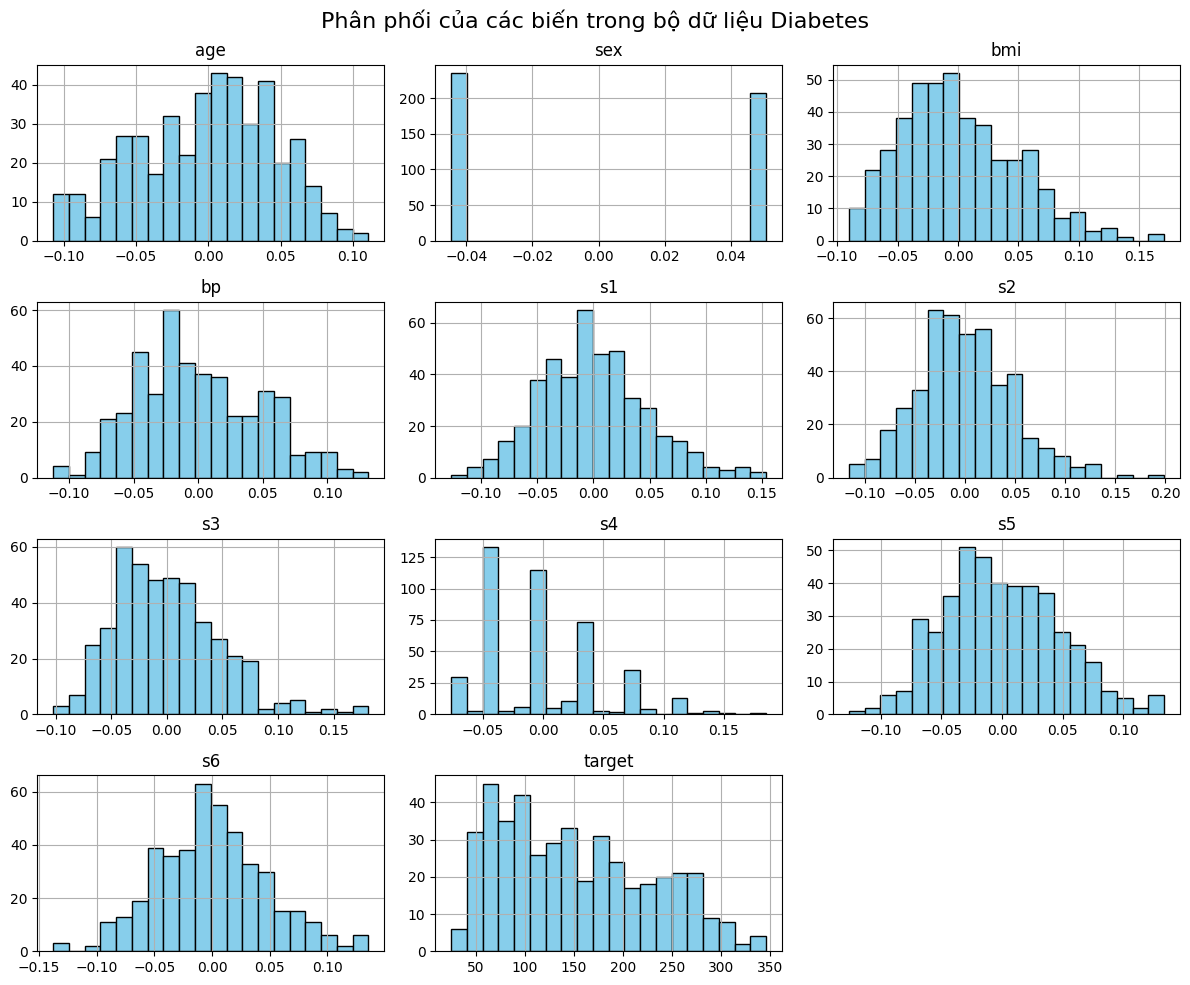

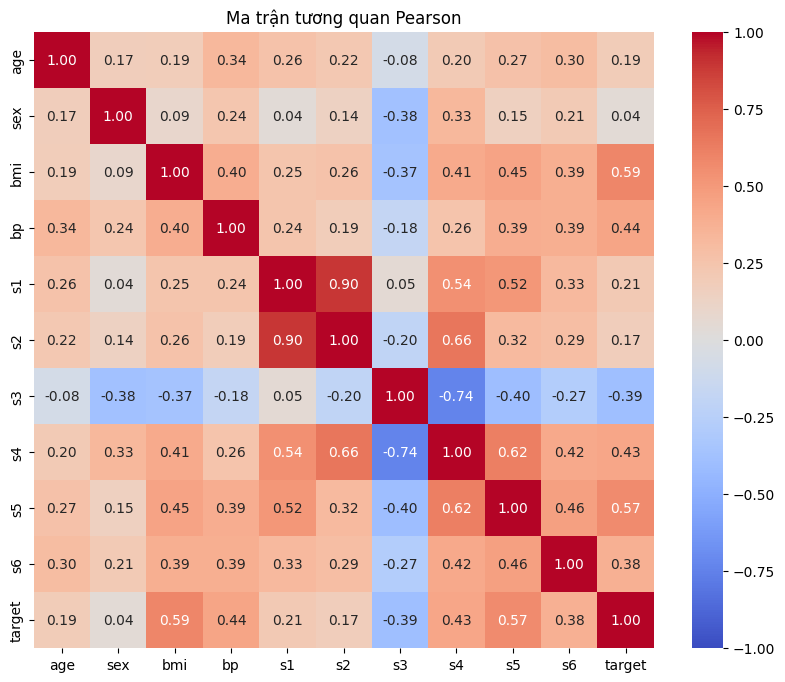

In [ ]:
# 1. Biểu đồ phân phối của tất cả các biến
df.hist(figsize=(12, 10), bins=20, edgecolor='black', color='skyblue')
plt.suptitle("Phân phối của các biến trong bộ dữ liệu Diabetes", fontsize=16)
plt.tight_layout()
plt.show()

# 2. Ma trận tương quan giữa các biến
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ma trận tương quan Pearson")
plt.show()


## Bước 6. Phát hiện ngoại lệ bằng IQR

Quy tắc IQR:

\[
IQR = Q_3 - Q_1
\]

Một giá trị thường được xem là ngoại lệ nếu nằm ngoài:

\[
[Q_1 - 1.5IQR,\; Q_3 + 1.5IQR]
\]


In [ ]:
outlier_summary = []

for col in feature_cols + ["target"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Số ngoại lệ theo IQR", "Ngưỡng dưới", "Ngưỡng trên"]
)

outlier_df

NameError: name 'feature_cols' is not defined


### Quan trọng

Không phải lúc nào ta cũng ** xóa ngoại lệ ngay lập tức**. Đối với bài toán này, ta không nên xóa dữ liệu ngoại lệ vì:
- Dataset nhỏ, chỉ có 442 mẫu.
- Một giá trị cực đoan có thể vẫn là quan sát hợp lệ.
- Xóa dữ liệu cần dựa trên hiểu biết miền bài toán, không chỉ dựa vào quy tắc thống kê.




## Bước 7. Phân tích tương quan

Hệ số tương quan Pearson nằm trong khoảng:

\[
-1 \le r \le 1
\]

- Gần `1`: tương quan tuyến tính dương mạnh.
- Gần `-1`: tương quan tuyến tính âm mạnh.
- Gần `0`: ít quan hệ tuyến tính.

Ta quan tâm hai loại tương quan:

1. **feature ↔ target**
2. **feature ↔ feature**


In [ ]:
corr = df.corr(numeric_only=True)

target_corr = corr["target"].drop("target").sort_values(key=np.abs, ascending=False)

print("Tương quan với target:")
display(target_corr.to_frame("corr_with_target"))


### Cách đọc kết quả

Các biến có trị tuyệt đối tương quan với `target` lớn hơn thường là ứng viên tốt để dự đoán bằng mô hình tuyến tính.

Tuy nhiên:

- tương quan cao **không đồng nghĩa nhân quả**;
- tương quan thấp **không chắc chắn vô dụng**, vì biến có thể đóng góp khi kết hợp với biến khác;
- Pearson chủ yếu đo **quan hệ tuyến tính**.


In [ ]:
# Vẽ ma trận tương quan
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Ma trận tương quan")
plt.tight_layout()
plt.show()



### Tại sao cần xem tương quan giữa các features?

Linear Regression có thể gặp vấn đề khi nhiều biến đầu vào tương quan rất mạnh với nhau. Hiện tượng này gọi là **multicollinearity**.

Hậu quả có thể gồm:

- hệ số hồi quy thay đổi mạnh khi dữ liệu thay đổi nhẹ;
- khó diễn giải vai trò riêng của từng feature;
- hệ số có thể lớn hoặc có dấu khó hiểu.


## Bước 8. Quan hệ giữa từng feature và target

Scatter plot giúp quan sát trực tiếp:

- xu hướng tăng/giảm;
- độ phân tán;
- quan hệ có gần tuyến tính không;
- có điểm ngoại lệ hay không.


In [ ]:
for col in feature_cols:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["target"], alpha=0.6)
    plt.xlabel(col)
    plt.ylabel("target")
    plt.title(f"{col} và target")
    plt.grid(alpha=0.2)
    plt.show()


# PHẦN 3. XÂY DỰNG MÔ HÌNH BASELINE

Ta xây dựng mô hình ban đầu với **10 đặc trưng gốc**. Đây sẽ là mô hình baseline để so sánh với mô hình sau Feature Engineering.


In [ ]:
# Tách bộ dữu liệu
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Khai báo mô hình
baseline_model = LinearRegression()

# Huấn luyện mô hình
baseline_model.fit(X_train, y_train)

# Dự đoán mô hình
baseline_pred = baseline_model.predict(X_test)

# Đánh giá mô hình
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline MAE  = {baseline_mae:.4f}")
print(f"Baseline MSE  = {baseline_mse:.4f}")
print(f"Baseline RMSE = {baseline_rmse:.4f}")
print(f"Baseline R²   = {baseline_r2:.4f}")



## Bước 9. Phân tích hệ số mô hình baseline


In [ ]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": baseline_model.coef_
}).sort_values("Coefficient", key=np.abs, ascending=False)

print("Intercept:", baseline_model.intercept_)
coef_df



# PHẦN 4. FEATURE ENGINEERING

## Feature Engineering là gì?

Feature Engineering là quá trình **tạo mới, biến đổi hoặc chọn lọc các đặc trưng đầu vào** để mô hình học được cấu trúc dữ liệu tốt hơn.

Ví dụ:

- bình phương một biến;
- tạo tương tác giữa hai biến;
- log-transform;
- gom nhóm;
- chọn subset đặc trưng.

Với Linear Regression, Feature Engineering đặc biệt hữu ích vì mô hình gốc chỉ mô tả quan hệ tuyến tính theo các features đã cung cấp.



## Bước 10. Tạo các feature phi tuyến đơn giản

Ta tạo:

- `bmi_squared = bmi²`
- `bp_squared = bp²`

Mục đích: cho phép mô hình tuyến tính mô tả một phần **độ cong** của mối quan hệ.


In [ ]:
df_fe = df.copy()

df_fe["bmi_squared"] = df_fe["bmi"] ** 2
df_fe["bp_squared"] = df_fe["bp"] ** 2

df_fe[["bmi", "bmi_squared", "bp", "bp_squared"]].head()



## Bước 11. Tạo feature tương tác

Ta tạo:

\[
bmi\_bp = bmi \times bp
\]

Feature này cho phép mô hình học rằng ảnh hưởng của `bmi` có thể thay đổi theo `bp`, và ngược lại.


In [ ]:
df_fe["bmi_bp"] = df_fe["bmi"] * df_fe["bp"]

df_fe[["bmi", "bp", "bmi_bp"]].head()


## Bước 12. Tạo feature tổng hợp từ nhóm serum

Để minh họa feature tổng hợp, ta thử tạo:

- `serum_mean`: trung bình `s1` đến `s6`
- `serum_std`: độ phân tán của nhóm `s1` đến `s6` trên từng mẫu

Ta gom nhiều biến có liên quan thành một số đặc trưng tổng quát.

In [ ]:
serum_cols = ["s1", "s2", "s3", "s4", "s5", "s6"]

df_fe["serum_mean"] = df_fe[serum_cols].mean(axis=1)
df_fe["serum_std"] = df_fe[serum_cols].std(axis=1)

df_fe[serum_cols + ["serum_mean", "serum_std"]].head()


## Bước 13. So sánh tương quan của các feature mới với target



In [ ]:
new_features = [
    "bmi_squared",
    "bp_squared",
    "bmi_bp",
    "serum_mean",
    "serum_std"
]

new_corr = df_fe[new_features + ["target"]].corr()["target"].drop("target")
new_corr.sort_values(key=np.abs, ascending=False).to_frame("corr_with_target")


## Bước 14. Huấn luyện mô hình sau Feature Engineering

Để so sánh basline, ta:

- giữ nguyên `test_size=0.2`
- giữ nguyên `random_state=42`



In [ ]:
X_fe = df_fe.drop(columns=["target"])
y_fe = df_fe["target"]

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42
)

fe_model = LinearRegression()
fe_model.fit(X_train_fe, y_train_fe)

fe_pred = fe_model.predict(X_test_fe)

fe_mae = mean_absolute_error(y_test_fe, fe_pred)
fe_mse = mean_squared_error(y_test_fe, fe_pred)
fe_rmse = np.sqrt(fe_mse)
fe_r2 = r2_score(y_test_fe, fe_pred)

print(f"Feature Engineering MAE  = {fe_mae:.4f}")
print(f"Feature Engineering MSE  = {fe_mse:.4f}")
print(f"Feature Engineering RMSE = {fe_rmse:.4f}")
print(f"Feature Engineering R²   = {fe_r2:.4f}")



## Bước 15. So sánh Baseline và Feature Engineering


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Feature Engineering"],
    "MAE": [baseline_mae, fe_mae],
    "RMSE": [baseline_rmse, fe_rmse],
    "R2": [baseline_r2, fe_r2]
})

comparison


### Cách phân tích kết quả

Nếu:

- MAE/RMSE giảm
- R² tăng

thì feature mới có thể giúp mô hình mô tả dữ liệu tốt hơn.

Nếu kết quả xấu đi, có thể vì:

- feature mới không thực sự hữu ích;
- dữ liệu nhỏ nên thêm feature làm tăng độ phức tạp;
- feature mới gây multicollinearity;
- quan hệ thực sự không được mô tả tốt bằng dạng feature đã tạo.

Lưu ý: **Feature Engineering là một giả thuyết cần kiểm chứng bằng thực nghiệm.**



# PHẦN 5. FEATURE SELECTION

Feature Selection khác với Feature Engineering:

- **Feature Engineering**: tạo hoặc biến đổi feature.
- **Feature Selection**: chọn những feature nên giữ lại.
Ta chọn một số feature có tương quan mạnh với `target`.


## Bước 16. Chọn feature dựa trên mức độ tương quan với `target`

In [ ]:
abs_corr = df.corr(numeric_only=True)["target"].drop("target").abs()
top_features = abs_corr.sort_values(ascending=False).head(5).index.tolist()

print("5 feature có |correlation| cao nhất với target:")
print(top_features)

## Bước 17. Huấn luyện mô hình sau Feature *Selection*

In [ ]:
X_selected = df[top_features]
y_selected = df["target"]

X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected,
    y_selected,
    test_size=0.2,
    random_state=42
)

selected_model = LinearRegression()
selected_model.fit(X_train_sel, y_train_sel)

selected_pred = selected_model.predict(X_test_sel)

selected_mae = mean_absolute_error(y_test_sel, selected_pred)
selected_rmse = np.sqrt(mean_squared_error(y_test_sel, selected_pred))
selected_r2 = r2_score(y_test_sel, selected_pred)

print(f"Selected Features MAE  = {selected_mae:.4f}")
print(f"Selected Features RMSE = {selected_rmse:.4f}")
print(f"Selected Features R²   = {selected_r2:.4f}")

## Bước 18. So sánh Baseline

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Feature Selection"],
    "MAE": [baseline_mae, selected_mae],
    "RMSE": [baseline_rmse, selected_rmse],
    "R2": [baseline_r2, selected_r2]
})

comparison

Ngoài ra, ta còn có phương pháp selection khác như:
- Recursive Feature Elimination (RFE)
- Lasso
- Mutual Information
- model-based feature importance
- cross-validation

Giống như Feature Engineering, Featue Selection cần kiểm chứng thực nghiệm.


# PHẦN 6. ĐÁNH GIÁ VÀ CHẨN ĐOÁN MÔ HÌNH


## Bước 19. So sánh giá trị thực tế và dự đoán


In [ ]:
result_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": baseline_pred,
    "Residual": y_test.values - baseline_pred
})

display(result_df.head(10))


In [ ]:
# Trực quan hóa
plt.figure(figsize=(7, 6))
plt.scatter(y_test, baseline_pred, alpha=0.7)

min_value = min(y_test.min(), baseline_pred.min())
max_value = max(y_test.max(), baseline_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title("Actual vs Predicted")
plt.grid(alpha=0.3)
plt.show()



### Cách đọc

- Điểm càng gần đường chéo thì dự đoán càng sát.
- Điểm nằm xa đường chéo tương ứng với sai số lớn.
- Nếu mô hình liên tục dự đoán thấp ở vùng target cao hoặc ngược lại, có thể có **systematic bias**.



## Bước 20. Residual Analysis

Residual:

\[
e_i = y_i - \hat{y}_i
\]

Một mô hình tuyến tính hợp lý thường có phần dư phân bố tương đối ngẫu nhiên quanh 0.

Nếu xuất hiện:

- dạng cong;
- hình phễu;
- cụm rõ rệt;

thì có thể tồn tại phi tuyến, phương sai không đồng nhất hoặc cấu trúc mà mô hình chưa học được.


In [ ]:
residuals = y_test.values - baseline_pred

plt.figure(figsize=(7, 5))
plt.scatter(baseline_pred, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Giá trị dự đoán")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()


## Bước 21. Phân phối residual


In [ ]:
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=20, edgecolor="black", alpha=0.8)
plt.xlabel("Residual")
plt.ylabel("Tần suất")
plt.title("Phân phối residual")
plt.grid(alpha=0.2)
plt.show()

print("Mean residual:", np.mean(residuals))



### Nhận xét

Nếu trung bình residual gần 0, mô hình không có xu hướng lệch tổng thể quá mạnh trên tập test.

Lưu ý ta cần phải kết hợp với các chỉ số đánh giá khác để kết luận mô hình tốt hay không như:

- MAE
- RMSE
- R²
- Actual vs Predicted
- Residual Plot



# PHẦN 7. TỔNG KẾT TOÀN BỘ PIPELINE

Full Pipline

1. **Xác định bài toán**
2. **Nạp dữ liệu**
3. **Kiểm tra chất lượng dữ liệu**
4. **EDA**
5. **Phân tích phân phối**
6. **Kiểm tra outlier**
7. **Phân tích correlation**
8. **Phân tích feature–target**
9. **Chia train/test**
10. **Xây dựng baseline**
11. **Feature Engineering**
12. **Feature Selection**
13. **Huấn luyện lại**
14. **So sánh các mô hình**
15. **Residual Analysis**
16. **Rút ra kết luận**
